<a href="https://colab.research.google.com/github/MahamedRamadan/CV-Course/blob/main/CNN_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Detected 5 classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Epoch 1/4


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


92/92 ━━━━━━━━━━━━━━━━━━━━ 131s 1s/step - accuracy: 0.3965 - loss: 1.3664 - val_accuracy: 0.5300 - val_loss: 1.1367
Epoch 2/4
92/92 ━━━━━━━━━━━━━━━━━━━━ 138s 1s/step - accuracy: 0.5327 - loss: 1.1250 - val_accuracy: 0.6281 - val_loss: 0.9689
Epoch 3/4
92/92 ━━━━━━━━━━━━━━━━━━━━ 124s 1s/step - accuracy: 0.6328 - loss: 0.9491 - val_accuracy: 0.6594 - val_loss: 0.9380
Epoch 4/4
92/92 ━━━━━━━━━━━━━━━━━━━━ 140s 1s/step - accuracy: 0.6907 - loss: 0.8079 - val_accuracy: 0.6485 - val_loss: 0.9243
Epoch 1/4
92/92 ━━━━━━━━━━━━━━━━━━━━ 102s 973ms/step - accuracy: 0.6686 - loss: 0.9581 - val_accuracy: 0.8256 - val_loss: 0.5456
Epoch 2/4
92/92 ━━━━━━━━━━━━━━━━━━━━ 135s 895ms/step - accuracy: 0.8355 - loss: 0.4680 - val_accuracy: 0.8597 - val_loss: 0.4138
Epoch 3/4
92/92 ━━━━━━━━━━━━━━━━━━━━ 141s 882ms/step - accuracy: 0.8685 - loss: 0.3551 - val_accuracy: 0.8569 - val_loss: 0.3717
Epoch 4/4
92/92 ━━━━━━━━━━━━━━━━━━━━ 84s 912ms/step - accuracy: 0.8869 - loss: 0.3047 - val_accuracy: 0.8733 - val_loss

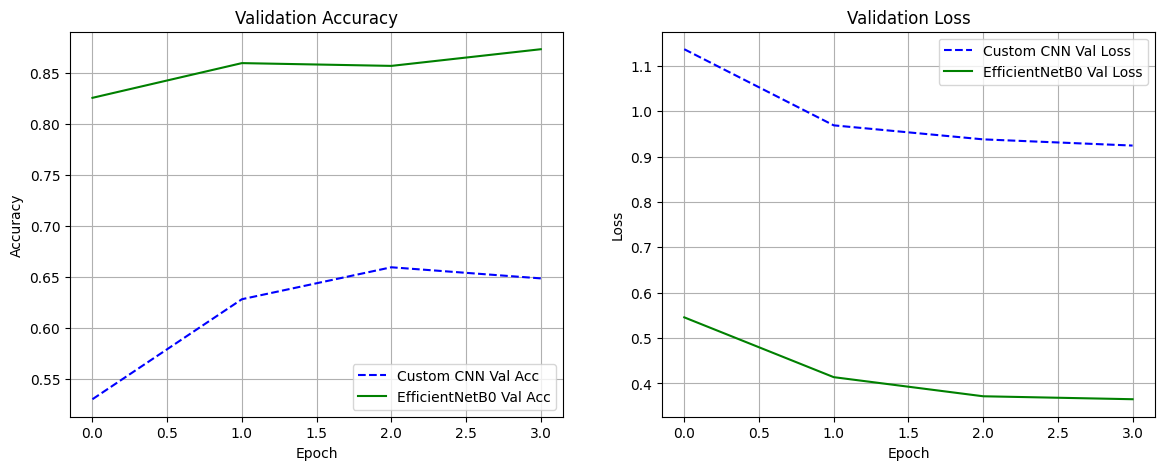

Custom CNN     -> Val Accuracy: 64.85% | Loss: 0.9243
EfficientNetB0 -> Val Accuracy: 87.33% | Loss: 0.3652


In [9]:
import pathlib
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Download Dataset cleanly to avoid directory conflicts
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
data_dir = tf.keras.utils.get_file('flower_photos', origin=dataset_url, untar=True)
data_dir = pathlib.Path(data_dir)

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 3

# 2. Data Pipelines
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

num_classes = len(train_ds.class_names)
print(f"Correctly identified classes ({num_classes}): {train_ds.class_names}")

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

# 3. Custom CNN Model
custom_cnn = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1./255),
    layers.Conv2D(32, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

custom_cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_custom = custom_cnn.fit(train_ds, validation_data=val_ds, epochs=EPOCHS)

# 4. Transfer Learning (EfficientNetB0)
inputs = layers.Input(shape=(128, 128, 3))
base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights='imagenet',
    input_tensor=inputs
)
base_model.trainable = False

x = layers.GlobalAveragePooling2D()(base_model.output)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)

efficientnet_model = models.Model(inputs, outputs)

efficientnet_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_eff = efficientnet_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS)

# 5. Performance Visualization
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_custom.history['val_accuracy'], 'b--', label='Custom CNN Val Acc')
plt.plot(history_eff.history['val_accuracy'], 'g-', label='EfficientNetB0 Val Acc')
plt.title('Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_custom.history['val_loss'], 'b--', label='Custom CNN Val Loss')
plt.plot(history_eff.history['val_loss'], 'g-', label='EfficientNetB0 Val Loss')
plt.title('Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

# 6. Evaluation Summary
loss_c, acc_c = custom_cnn.evaluate(val_ds, verbose=0)
loss_e, acc_e = efficientnet_model.evaluate(val_ds, verbose=0)

print("=" * 50)
print(f"Custom CNN     -> Val Accuracy: {acc_c*100:.2f}% | Loss: {loss_c:.4f}")
print(f"EfficientNetB0 -> Val Accuracy: {acc_e*100:.2f}% | Loss: {loss_e:.4f}")
print("=" * 50)